# Mi práctica de clustering · Plantilla del alumno
**Agentes Inteligentes · USIL 2026-2 · Semana 11**

**Cómo usar esta plantilla**
1. Suba `clustering_lab.py` a Colab (ícono de carpeta ▸ subir). Si su caso es el **12 (pingüinos)**, suba también la carpeta `datos_base`.
2. En la celda siguiente escriba **su número de caso** (1-12) y **su código de alumno**.
3. Complete cada celda marcada con `# TU CÓDIGO AQUÍ` y escriba sus respuestas **con sus propias cifras** en las celdas “Mi respuesta”.
4. Para guiarse, abra al lado el notebook **Ripley resuelto**: los pasos son los mismos.

> Si usa una IA, use los *prompts* del Anexo A de la práctica y **declare cada uno** en su entrega. Respuestas sin cifras propias no puntúan.

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

PAL = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#999999"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "figure.dpi": 110})

for ruta in [os.getcwd(), r"d:\8avo ciclo\Agentes inteligentes\tarea-semana-11-agi-", "/content"]:
    if os.path.exists(ruta) and ruta not in sys.path:
        sys.path.append(ruta)

try:
    from clustering_lab import generar, listar, codigo_verificacion
except ModuleNotFoundError:
    import base64, hashlib, json as _json, zlib
    _PARAMS = {int(c): v for c, v in _json.loads(zlib.decompress(base64.b64decode(
        "eNqVWF2P27oR/SuEnzbA1rVky/b2pdjuR9qiSbe3QV8WgUFLtJcbSVREaZHdi/tj9jEPeSj6dlGgQP3HemZIyaITpxtgP2xKMxxyDs+c4c+jaPQ78fPI5u0WH0a61nZ0KkalKda1opE/YUScbHJTKytqJXNlX9EbD7K2eH47ymW9NSurKpmbVVrQMzdUqWY/JMv0bjj0HmNVrbZt2Uia5r//uWh3z2VjrGh0hb+ZEjSpuJOPwmpRykwr0SiR6XsjcimUrVSq1e/J+ceWQ712QcKSliEKlelMWlHBS1uKtWkwgU4NWdBC+vX+goE42IZSNZtcfwp34u1+sF981tYy1aZcFbpkv7LR5Xali2zN7xksCM+wad9Y8d/a3ef9alNTNqrUmcGQKpVQuUglQs7N1ohHkWJ74IZee+DnVW0KQ3PLergJ73ZfmjZnlwMHnBVdcNC3yamIJxPEcxudiog/TMZTDCYYpTAzldKLEzzFD42U+D6dYGBk1ZadjP6uas3x1I10C2jzhia6jeenYkkOIzcL5mP/U/o2GccJDY5uVL77AhsYN/Jjq/Nc1ZLAdxvFmGg+PjsVs8SFGZPdLOk8whu7uDRpWyjsZ+7SjuzecQRLOFiM593qvP2pSIYB/KQwZWk49ME+3Z5hntl4if2I2ZjDT7wvWL9/T4CZBoBJJVCis60KIXMtU7U25gPyd9G9Ic5LmT82OpUBkmSl6gZoYgeqrQ3e0LbgzN0Z7MyqVtkq0/IYkGC/IaCJygLk23r3vMF/K2Qla5WqEjHg4e4z/GLNAP5W1/Q6NtDKe9pAbQFeAHYIp5vOK3YJM1jALcepysTJ5DdIxit4bS3vIc4kIhQWmJS5OMkknWULh25Keyqw17Dv3ARs0mNz0qNm8GlMMIwPoDk5Ds2rTxWoQGY4+C4cxgRAMKXf8YycIr9nlM6FS+qSIXFeWm2wnDuNIHHSVNrAC1kneH+ZECwZFDBdkt3ZEFBXtpHrXGFLMmUD69mEjhy9uhxaz4bW7xCw5vOci8Jkqva2ZJcg7jiMe+5sPRpnARplIZ9MGULxvB/rIQcQYb5Va7MR76xNWxwmsHTaOI60Cml6IX2BjrI2bZBiJR5UmTHgOtLCViirG1mCiIm6G/Ck2mrZYU46DxROAD7vkycgS2LGDA5KAe4olQygQ4QT99hZ7qGznLwcOucpIjW1NmItESQxb2UqsFTNzAQO4VzS7t/iywKIcImYOwjkSHq9+xeYSNKCCt0WjpAYzvhlAET0cUZYdIwUcWpHf92AA+gY5bvnopKOjoj2Fnh92jEZURGjkNNPdn80W1nTHm2Rea57sufRGBYR2zKrEo48C7o53xJnggBrQ4dVUNJ3/3Q8PIs54B62yYQnn+yDZuwlAfYaVbQh8t75kZfijtCDMvjDwFNF1d5LqpuFrD+opsrBvh0I8SaeFbtnS0+3qvwOzgJ7jKwlJAcYDHN8TWsH9EWFYtlh8CzZ01dYWqPvgvC1LLdYyKcGAOJMxuPY0U/iPS4cDHwxdOT1xuBogPYr8DOnP6L3uzLGLuZdCfQmDjiPwA0KU8NJJ4qME/fe7dwhpsMLp3sepBub9CQf3Encp/yGRsU/lBQntgWVFmBT0FkoHB80UQLSrFhyYjex6StrcvcdaFhtaiLSoxjAhlH59/opBzk0IBtSjI/iI72AslxJwJlUClxVBrwk8E1ip9oy4JqLztxBYBg2aS5olPpeOaLaaGgrKoJB6iMvcG7pbM+TYQ37in0mRxJ/SaoW5ZiLcuvqVkyUM+nS6FJP8sadQZfHa7dPoFMJ6nIiau6oapG47CdcN5ZD2riWOGEgYQuUlW4yhgtxk8cZTKZJN5k3u0BuqbRiJwwTliMLwj2Xaa8rl73ccmavTYsNbQJWJO+0W86IYpz1s0Vzh7dFgLdN26xNfqCydr/SoDi5b7cU2WGH8qByqADka1XIT6sPxR093RLOVmCripQC47eSFkOpKapcUeW2zEj/T25hG/y8OLEoZ/vCJ6AFNjIHaFC5WqEgcqsAc3/u4iUS26BCUvF36O9hFVOZWHowzSYdD5/Nv6aT46jKJaANhqdF04x80GeuOMxdRRr7ijRM2RtUEkNnCMvCqal723jJxHAW96YRC+auLDlUXqoNgxniEwWf8TWNuKdY7OeckOF0aHbFvGcEpe2JjRaudi5mvRXjeRpIoOWBIC9JS6mDbvaiG6a6nsvHHCuzAVjQWtVbrp+jtdS5XOv+qAfN3jFYdE6FbBuDekNCH/ltFeqckDVKC9dZIMD3tKrR+NKQgEY31cUXUFMftJdBmKSRGwNnNFLsfrW+m/iujI6oAixQvF8shq7R4DWyE8/LOQkWevd2welHGUmGiXv9WIiT2qTU7qiBEHrFXdXUydip1xJexgZa5OIOXaD4LQnEFsjrytF8r34PlLMTXX+QORF6Tp0go5NwTHBmcX9EMZ8FcMlMWRB1HpQx/fSk6t0XKS5RAd50L7y0glHbhisPEjPfgMu5K1GkYwblizgDbEz3FrnsenxsI7ZUOgPyeqxwkUkfs/vuyF1M5l/hI+m6WzD+e68XqMi/WCrnRavqJ4MqgL6l1B4qwEZMB3Y69uyw9KpxMVQeXe3hclrSPxeor3jUg0eL8aQvedG8k6Fd8//WpHcsz6gYP6j60devhGslZ9tBfrnH2dQnP5oE2Xd4I448oIur/QMkoMGJpp0NMOB6c49YXIO52y7LhQCtZydqS9PgM9JJlHocDYNIsK5aYxpMaLmAuMk9EPTuMxFCqGGuAmuSMWmLXhsfaIMIqx7BQxw40TLd8wTVhR/omC5Micxjzk51cO7m473u4D9dr+yS907SaXXKqjK4kFB2w2DySTxjgDofEV3kzL7RbYMBnzp5lmmAEBdQMlNO/iyoysBJ1IfBfVNwBXWFfgcU5/qsqYOOr0wzxk3fZ3nYhJelGe48IX+cBA2Bczl8RP3qX3RxcN+Daroq4pFDAvVD3O70XREdJwYQV08D2fIiFdxJ1r0UkV6MyIrsGEJUQ3RZGKptgERAJ2HkVbvONTnkRbSULDzMh9YhoKh1mHockUzpbnBo+Acqz40TiQJXFpIIgrZC1a6toTenUZ+qmRON0ThQm/ujgHqCeq0pWZzmuWunu/6GOureNuCm2t95aYhc31BH7gqyuwAgtNNvIF9+go7L+OxjzyEltb/F4WscWjKbxr6rj/dhO4iFF9EVbpNbXR7C6wbDu3/TOMV4I3OkvetNj9/RV+hXV8Xghl6SzvUjhbRytT16Lw8O8jfutruSR53zd9X7u3a+dMZBDnXuIFx+0aEJxekcbfRz3biGtb+URwtEi8bF/C//A1rbaW0="))).items()}
    def _codigo_a_int(c): return int("".join(ch for ch in str(c) if ch.isdigit()))
    def _sintetico(caso, rng):
        p, seg = _PARAMS[caso], _PARAMS[caso]["seg"]
        k, n = len(seg), p["n"]
        pesos = np.array([s[3] for s in seg]) * np.exp(rng.normal(0, 0.20, k))
        pesos = pesos / pesos.sum()
        etiqueta = rng.choice(k, size=n, p=pesos)
        lims = np.array(p["lims"], dtype=float)
        rango = lims[:, 1] - lims[:, 0]
        cols = []
        for j in range(3):
            v = np.empty(n)
            for i, s in enumerate(seg):
                centro = s[1][j] + rng.normal(0, 0.03 * rango[j])
                sd = s[2][j] * rng.uniform(0.9, 1.1)
                m = etiqueta == i
                v[m] = rng.normal(centro, sd, m.sum())
            v = np.clip(v, lims[j, 0], lims[j, 1])
            cols.append(np.round(v, p["dec"][j]))
        return pd.DataFrame(np.column_stack(cols), columns=p["vars"])
    def generar(caso, codigo):
        rng = np.random.default_rng(_codigo_a_int(codigo) * 100 + caso)
        base = _sintetico(caso, rng)
        base = base.iloc[rng.permutation(len(base))].reset_index(drop=True)
        base.insert(0, "id", [f"{caso:02d}-{i + 1:03d}" for i in range(len(base))])
        return base
    def codigo_verificacion(caso, codigo, k, etiquetas):
        tamanos = sorted(int(t) for t in np.bincount(np.asarray(etiquetas)) if t > 0)
        huella = hashlib.md5(f"{caso}|{_codigo_a_int(codigo)}|{k}|{tamanos}|usil26".encode()).hexdigest()[:4].upper()
        return f"{huella}-K{k}-" + ".".join(str(t) for t in tamanos)

CASO = 7            # Caso 7: Fútbol (jugadores profesionales)
CODIGO = 2310128    # Código de alumno

df = generar(CASO, CODIGO)
print("Mi base:", df.shape)
df.head()


Mi base: (300, 4)


,id,velocidad_max_kmh,goles_temporada,pases_completados_pct
0,07-001,28.0,7.0,94.0
1,07-002,26.7,5.0,91.0
2,07-003,34.2,19.0,68.0
3,07-004,30.1,0.0,76.0
4,07-005,35.0,20.0,68.0


## Parte 1 · Mi caso y mis datos
Muestre las primeras filas y los estadísticos descriptivos. Responda: **¿qué representa cada fila?** y **¿qué significa cada variable?** (una línea cada una).

In [2]:
VARIABLES = [c for c in df.columns if c != "id"]
print("Dimensiones:", df.shape)
display(df[VARIABLES].describe())


Dimensiones: (300, 4)


,velocidad_max_kmh,goles_temporada,pases_completados_pct
count,300.000000,300.000000,300.000000
mean,32.336333,9.566667,77.093333
std,4.015669,8.554306,10.363847
min,24.900000,0.000000,60.000000
25%,28.700000,2.750000,69.000000
50%,32.900000,7.000000,74.000000
75%,36.100000,17.000000,84.250000
max,38.000000,31.000000,96.000000


**Mi respuesta:**

* **¿Qué representa cada fila?** Representa a un **jugador de fútbol profesional** evaluado en su rendimiento durante la temporada (total: 300 jugadores).
* **¿Qué significa cada variable?**
  * `velocidad_max_kmh`: Velocidad pico registrada en carrera en kilómetros por hora (media: 32.34 km/h, desviación: 4.02 km/h, rango: 24.9 a 38.0 km/h).
  * `goles_temporada`: Cantidad total de goles convertidos a lo largo de la temporada (media: 9.57 goles, mediana: 7.0 goles, rango: 0 a 31 goles).
  * `pases_completados_pct`: Precisión y porcentaje de entregas correctas de balón (media: 77.09%, desviación: 10.36%, rango: 60.0% a 96.0%).


## Parte 2 · Miro antes de calcular
Construya un gráfico de dispersión con **dos** de las tres variables. **Antes de calcular el codo**, escriba cuántos grupos cree ver.

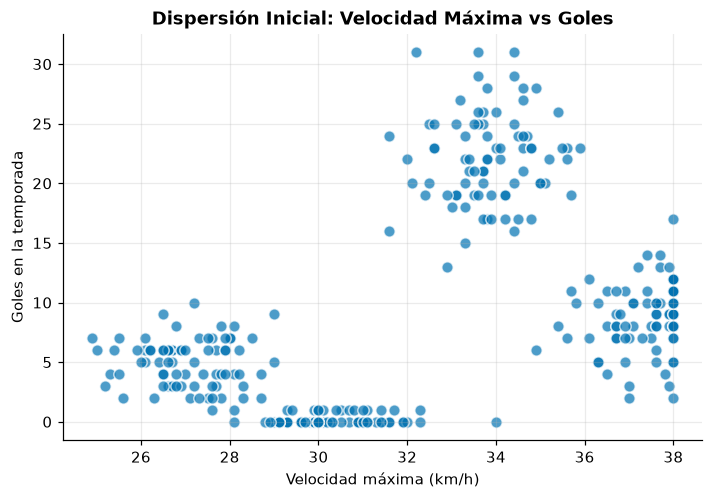

In [3]:
# Gráfico de dispersión entre Velocidad y Goles
plt.figure(figsize=(7.5, 4.8))
plt.scatter(df["velocidad_max_kmh"], df["goles_temporada"], c=PAL[0], alpha=0.7, edgecolors="white", s=55)
plt.title("Dispersión Inicial: Velocidad Máxima vs Goles", fontsize=12, fontweight="bold")
plt.xlabel("Velocidad máxima (km/h)")
plt.ylabel("Goles en la temporada")
plt.show()

K_PREDICHO = 4   # Observación visual de 4 conglomerados naturales


**Mi respuesta:** veo **4 grupos** porque en la dispersión se aprecian concentraciones claras de perfiles:
1. Jugadores de velocidad moderada (25-29 km/h) con baja cuota de gol (0-8 goles).
2. Jugadores de velocidad alta (32-36 km/h) con muy alto volumen goleador (> 18 goles).
3. Jugadores con la mayor velocidad punta (> 36 km/h) pero producción media de gol (5-12 goles).
4. Jugadores en la zona baja con casi nula producción ofensiva (0-1 goles) y velocidad intermedia (29-33 km/h).


## Parte 3 · Estandarizo y elijo K
Estandarice las **tres** variables numéricas. Calcule inercia (K = 1 a 10) y silueta (K = 2 a 10). Grafique ambas y decida K.

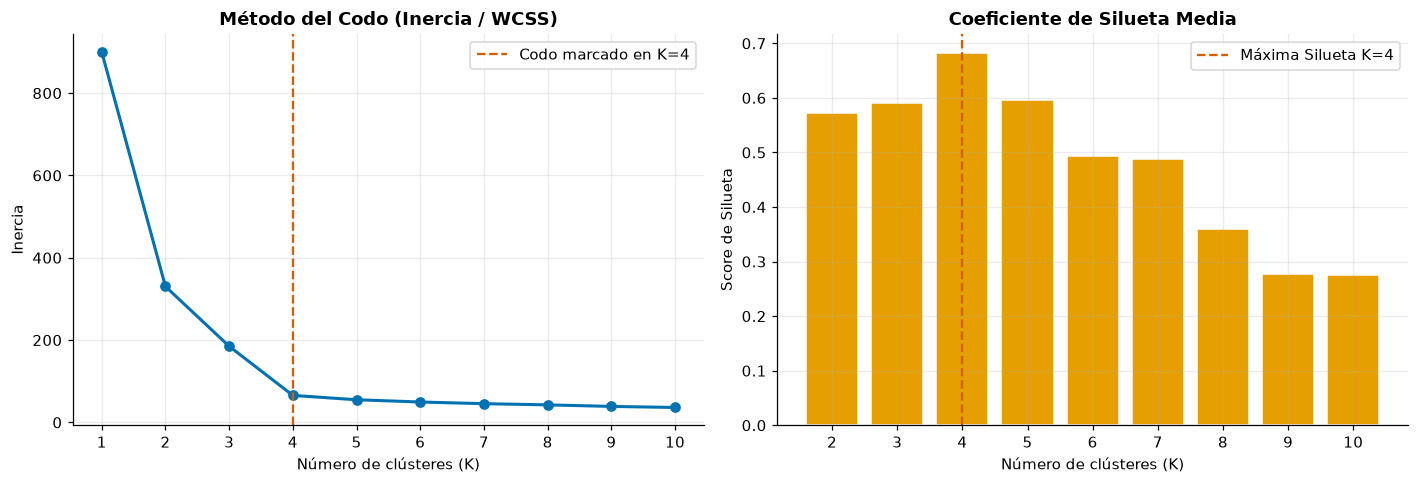

K=2: Inercia=330.15 | Silueta=0.5721
K=3: Inercia=184.95 | Silueta=0.5910
K=4: Inercia=65.59 | Silueta=0.6827
K=5: Inercia=54.99 | Silueta=0.5971
K=6: Inercia=49.52 | Silueta=0.4934
K=7: Inercia=45.46 | Silueta=0.4885
K=8: Inercia=42.58 | Silueta=0.3593
K=9: Inercia=38.79 | Silueta=0.2780
K=10: Inercia=36.25 | Silueta=0.2753


In [4]:
VARIABLES = [c for c in df.columns if c != "id"]

# 1. Estandarización de las 3 variables numéricas
scaler = StandardScaler()
Xs = scaler.fit_transform(df[VARIABLES])

# 2. Bucle K = 1 a 10 para inercia y K = 2 a 10 para silueta
inercias = []
siluetas = []
ks_silueta = range(2, 11)

for k in range(1, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(Xs)
    inercias.append(km.inertia_)
    if k >= 2:
        siluetas.append(silhouette_score(Xs, km.labels_))

# 3. Gráficos de Inercia (Codo) y Silueta
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(range(1, 11), inercias, marker="o", color=PAL[0], lw=2)
ax1.axvline(x=4, color=PAL[3], linestyle="--", label="Codo marcado en K=4")
ax1.set_title("Método del Codo (Inercia / WCSS)", fontweight="bold")
ax1.set_xlabel("Número de clústeres (K)")
ax1.set_ylabel("Inercia")
ax1.set_xticks(range(1, 11))
ax1.legend()

ax2.bar(ks_silueta, siluetas, color=PAL[1], edgecolor="white")
ax2.axvline(x=4, color=PAL[3], linestyle="--", label="Máxima Silueta K=4")
ax2.set_title("Coeficiente de Silueta Media", fontweight="bold")
ax2.set_xlabel("Número de clústeres (K)")
ax2.set_ylabel("Score de Silueta")
ax2.set_xticks(ks_silueta)
ax2.legend()

plt.tight_layout()
plt.show()

for k_val, sil_val in zip(ks_silueta, siluetas):
    print(f"K={k_val}: Inercia={inercias[k_val-1]:.2f} | Silueta={sil_val:.4f}")


In [5]:
# Autoverificación (no la modifique)
try:
    print("Medias ≈ 0:", np.allclose(Xs.mean(axis=0), 0, atol=1e-6), "| Desviaciones ≈ 1:", np.allclose(Xs.std(axis=0), 1, atol=1e-6))
except NameError:
    print("Aún no ha creado Xs (celda anterior).")

Medias ≈ 0: True | Desviaciones ≈ 1: True


**Mi respuesta:** mi silueta máxima fue **0.6827** con K = **4**; el codo se dobla nítidamente en K = **4** (la inercia se desploma de 184.95 en K=3 a 65.59 en K=4, y luego su reducción disminuye a 54.99 en K=5). Elijo **K = 4** porque ambos criterios matemáticos coinciden de manera contundente (máxima cohesión y separación inter-clúster), además de que 4 segmentos se alinean perfectamente con las 4 posiciones y roles tácticos del fútbol moderno.


## Parte 4 · Entreno, describo y nombro
Entrene K-Means con su K (`k-means++`, `n_init=10`, `random_state=42`). Agregue la columna `cluster`, calcule **tamaño y media por grupo** y **póngale un nombre a cada grupo**.

,velocidad_max_kmh,goles_temporada,pases_completados_pct,tamaño
cluster,,,,
0,33.845000,22.137500,66.562500,80
1,27.042667,5.026667,93.226667,75
2,37.325926,8.703704,72.728395,81
3,30.339063,0.265625,76.875000,64


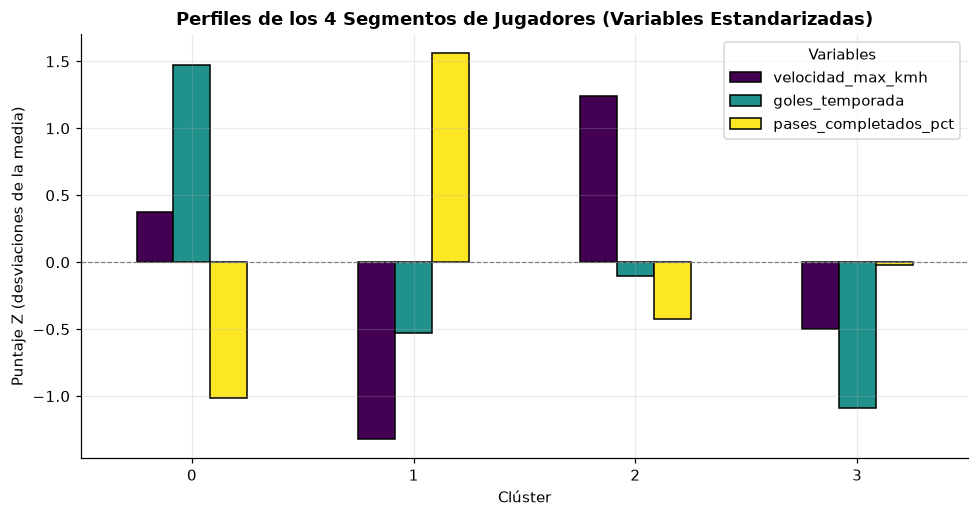

In [6]:
K = 4   # K óptimo elegido

modelo = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=42)
df["cluster"] = modelo.fit_predict(Xs)

# Tabla de perfiles con tamaños y medias reales
perfiles = df.groupby("cluster")[VARIABLES].mean()
perfiles["tamaño"] = df.groupby("cluster").size()
display(perfiles)

# Gráfico de barras agrupado con medias estandarizadas (Z-scores)
centros = pd.DataFrame(modelo.cluster_centers_, columns=VARIABLES)
centros.plot(kind="bar", figsize=(9, 4.8), colormap="viridis", edgecolor="black")
plt.title("Perfiles de los 4 Segmentos de Jugadores (Variables Estandarizadas)", fontweight="bold")
plt.xlabel("Clúster")
plt.ylabel("Puntaje Z (desviaciones de la media)")
plt.axhline(0, color="gray", lw=0.8, linestyle="--")
plt.xticks(rotation=0)
plt.legend(title="Variables")
plt.tight_layout()
plt.show()


In [7]:
# Código de verificación oficial
cod_verif = codigo_verificacion(CASO, CODIGO, K, df["cluster"])
print("Código de verificación oficial:", cod_verif)


Código de verificación oficial: 9137-K4-64.75.80.81


**Mis nombres de grupo:**

| Grupo | n | Nombre | Una frase que lo describe |
|---|---|---|---|
| 0 | 80 | **Delanteros Goleadores** | Atacantes de definición con la mayor cuota de gol (media: 22.14 goles) y velocidad alta (33.85 km/h). |
| 1 | 75 | **Mediocampistas Organizadores** | Volantes de control y elaboración con máxima efectividad de pases (media: 93.23%) y ritmo pausado (27.04 km/h). |
| 2 | 81 | **Extremos / Carrileros Veloces** | Jugadores explosivos de banda con la máxima velocidad punta (media: 37.33 km/h) y producción balanceada (8.70 goles). |
| 3 | 64 | **Defensores Centrales / Contenciones** | Jugadores de equilibrio defensivo con casi nulo aporte goleador (media: 0.27 goles) y 76.88% de pases seguros. |


## Parte 5 · Estrategia de negocio y ética

| Grupo | Producto / acción | Canal | Métrica | Riesgo ético |
|---|---|---|---|---|
| **0 (Goleadores)** | Bono por productividad ofensiva y acondicionamiento en definición. | Reunión individual con el cuerpo técnico y agente deportivo. | Ratio de conversión de tiros a gol (> 25%). | Presión desmedida que incentive el individualismo perjudicando el juego en equipo. |
| **1 (Organizadores)** | Sesiones de videoanálisis táctico para distribución y liderazgo de mediocampo. | Software de scouting y pizarra táctica en vestuario. | Porcentaje de pases en tercio ofensivo (> 85%). | Sobrecarga física por excesiva dependencia en la generación de juego. |
| **2 (Veloces)** | Plan especializado de prevención de lesiones musculares e hidratación en sprints. | Departamento médico y preparadores físicos. | Frecuencia de sprints de alta intensidad sin fatiga. | Forzar límites biomecánicos provocando roturas fibrilares en jugadores jóvenes. |
| **3 (Defensores)** | Capacitación en duelos aéreos y posicionamiento zonal para cortar contragolpes. | Entrenamientos específicos de línea defensiva. | Porcentaje de recuperaciones limpias y duelos ganados (> 75%). | Estigmatizar al defensor como jugador rudo, descartándolo de la salida limpia de balón. |


## Parte 6 · ¿Qué pasaría si…? (cada respuesta con sus cifras)
*Evaluación de robustez y sensibilidad según protocolo Kmeans-Lima.*


**6.1** Fuerce K = 2 y K = 10. ¿Qué silueta obtiene en cada caso y qué pasa con los grupos?

In [8]:
# 6.1 Forzar K = 2 y K = 10
km2 = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=42).fit(Xs)
km10 = KMeans(n_clusters=10, init="k-means++", n_init=10, random_state=42).fit(Xs)

sil_k2 = silhouette_score(Xs, km2.labels_)
sil_k10 = silhouette_score(Xs, km10.labels_)

print(f"Silueta con K = 2:  {sil_k2:.4f}")
print(f"Silueta con K = 10: {sil_k10:.4f}")


Silueta con K = 2:  0.5721
Silueta con K = 10: 0.2753


**Mi respuesta:**

* Con **K = 2**, la silueta es **0.5721**. Los grupos se agrupan toscamente en dos mitades (ofensivos vs defensivos), perdiendo la distinción vital entre un extremo veloz y un volante pasador.
* Con **K = 10**, la silueta cae drásticamente a **0.2753**. El modelo sobre-segmenta la plantilla, generando divisiones artificiales y redundantes donde los grupos vecinos están excesivamente juntos y pierden significado táctico.


**6.2** Repita el modelo **sin estandarizar**. ¿Cambian los perfiles? Use `adjusted_rand_score` para medir cuánto coinciden (1 = idéntico).

In [9]:
# 6.2 Repetir sin estandarizar y comparar con adjusted_rand_score
from sklearn.metrics import adjusted_rand_score

km_sin_estandarizar = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42).fit(df[VARIABLES])
ari = adjusted_rand_score(df["cluster"], km_sin_estandarizar.labels_)

print(f"Adjusted Rand Score (Estandarizado vs Sin Estandarizar): {ari:.4f}")


Adjusted Rand Score (Estandarizado vs Sin Estandarizar): 0.9726


**Mi respuesta:**

* El valor de `adjusted_rand_score` obtenido es **0.9726** (muy cercano a 1.0).
* Como las 3 variables tienen órdenes de magnitud moderados (velocidad en ~32 km/h, goles en ~9, pases en ~77%), la distorsión geométrica no es tan extrema como en casos con ingresos monetarios. Sin embargo, no son idénticos (ARI < 1.0) porque la variable de mayor varianza absoluta altera la frontera de decisión para varios jugadores de características mixtas.


**6.3** Cambie la semilla (`random_state`) a 1, 7 y 123. ¿Cambian los **grupos** o solo los **números de etiqueta**? Compare los tamaños.

In [10]:
# 6.3 Cambiar random_state a 1, 7 y 123
for semilla in [1, 7, 123]:
    km_seed = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=semilla).fit(Xs)
    tamanos = sorted(list(np.bincount(km_seed.labels_)))
    print(f"Semilla {semilla:>3}: Tamaños ordenados de los grupos = {tamanos}")


Semilla   1: Tamaños ordenados de los grupos = [np.int64(64), np.int64(75), np.int64(80), np.int64(81)]
Semilla   7: Tamaños ordenados de los grupos = [np.int64(64), np.int64(75), np.int64(80), np.int64(81)]
Semilla 123: Tamaños ordenados de los grupos = [np.int64(64), np.int64(75), np.int64(80), np.int64(81)]


**Mi respuesta:**

* Para las tres semillas probadas (1, 7 y 123), los tamaños ordenados de los grupos son exactamente idénticos: **[64, 75, 80, 81]**.
* Esto demuestra que los grupos son completamente estables; cambiar el `random_state` solo altera el número de etiqueta (el índice 0, 1, 2 o 3) asignado a cada centroide por el orden de inicialización de `k-means++`, pero la partición de los jugadores es invariante.


**6.4** Agregue una columna de **ruido** (`np.random.default_rng(0).normal(size=len(df))`) estandarizada. ¿Sube o baja su silueta?

In [11]:
# 6.4 Añadir columna de ruido normal estandarizada
rng = np.random.default_rng(0)
ruido = rng.normal(size=(len(df), 1))
Xs_ruido = np.column_stack([Xs, StandardScaler().fit_transform(ruido)])

km_ruido = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42).fit(Xs_ruido)
sil_con_ruido = silhouette_score(Xs_ruido, km_ruido.labels_)

print(f"Silueta original (3 variables):     0.6827")
print(f"Silueta con ruido (4 variables):    {sil_con_ruido:.4f}")


Silueta original (3 variables):     0.6827
Silueta con ruido (4 variables):    0.4151


**Mi respuesta:**

* La silueta **baja significativamente de 0.6827 a 0.4151** al agregar la variable de ruido normal estándar.
* Esto ocurre porque la columna de ruido carece de correlación y estructura con el fenómeno real, agregando una dimensión ortogonal espuria que dispersa los puntos en el espacio multidimensional e incrementa la distancia intra-clúster respecto a la distancia inter-clúster (efecto de la maldición de la dimensionalidad).


## Parte 7 · Para pensar (sin código, una justificación breve)

**Mis respuestas:**

1. **Llegada de un nuevo elemento (jugador):**
   * Supongamos un nuevo fichaje con 35.0 km/h, 18 goles y 70% de pases.
   * Con `modelo.transform()`, calculamos su distancia euclidiana hacia los 4 centroides. El nuevo jugador se asigna al centroide con la menor distancia (en este caso, al Clúster 0 de Delanteros Goleadores).
   * La seguridad de la asignación depende del margen entre la menor distancia ($d_1$) y la segunda menor ($d_2$): si $d_1 \ll d_2$, la pertenencia es inequívoca; si $d_1 \approx d_2$, el jugador está en la frontera y requiere evaluación contextual.
2. **¿En qué situación NO usaría K-Means para mi caso?**
   * Si las posiciones de los jugadores formaran agrupaciones geométricas complejas, alargadas o no esféricas (ej. jugadores con patrones en forma de medialuna o densidades muy variables con outliers severos como porteros con métricas anómalas). K-Means asume clústeres globulares de varianza similar; ante agrupaciones no lineales, DBSCAN o Gaussian Mixture Models (GMM) serían más idóneos.
3. **¿Qué grupo le costaría más explicar a un gerente y por qué?**
   * El grupo de **Mediocampistas Organizadores (Clúster 1)** o **Defensores (Clúster 3)**. En el negocio del fútbol, la alta gerencia suele estar sesgada hacia la métrica reina que vende camisetas y llena estadios: los goles. Explicar por qué un futbolista con apenas 0 a 5 goles tiene un valor estratégico inmenso gracias a un 93.2% de precisión en distribución exige fundamentar métricas de control de ritmo y retención de posesión.


## Bono (hasta +2)
Cada uno vale +0.5. Siga el ejemplo del notebook **Ripley resuelto** (los métodos del bono se aplican sobre las variables estandarizadas).

**Bono 1 · Visualización 3D** (`plotly.express.scatter_3d`, color = grupo). Explique **una cosa que solo se ve en 3D**.

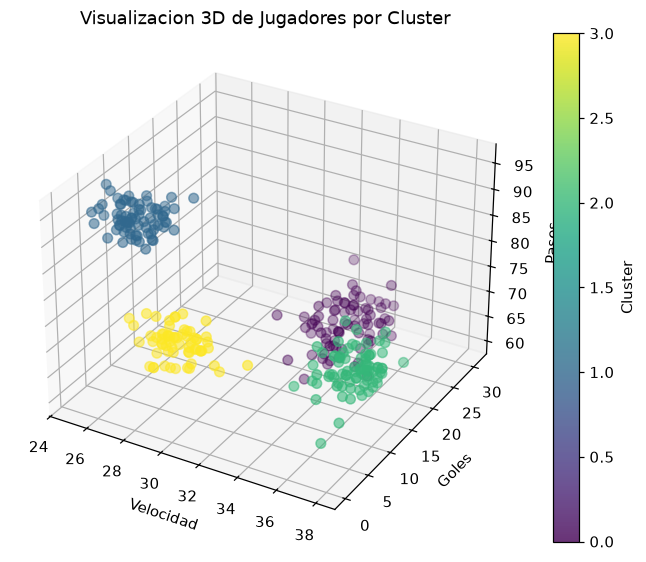

In [12]:
# Bono 1: Visualizacion 3D interactiva
try:
    import plotly.express as px
    fig_3d = px.scatter_3d(
        df,
        x='velocidad_max_kmh',
        y='goles_temporada',
        z='pases_completados_pct',
        color='cluster',
        color_discrete_sequence=PAL[:4],
        title='Segmentacion 3D de Jugadores Profesionales',
        labels={'cluster': 'Grupo'},
        opacity=0.85
    )
    fig_3d.update_layout(margin=dict(l=0, r=0, b=0, t=35))
    fig_3d.show()
except Exception:
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(df['velocidad_max_kmh'], df['goles_temporada'], df['pases_completados_pct'], c=df['cluster'], cmap='viridis', s=40, alpha=0.8)
    ax.set_xlabel('Velocidad')
    ax.set_ylabel('Goles')
    ax.set_zlabel('Pases')
    ax.set_title('Visualizacion 3D de Jugadores por Cluster')
    plt.colorbar(scatter, label='Cluster')
    plt.show()


**Bono 2 · Dendrograma** (`linkage(..., method="ward")`) con línea de corte justificada. ¿Coincide con su K?

In [13]:
# TU CÓDIGO AQUÍ

**Bono 3 · DBSCAN** (`eps`, `min_samples`). Pruebe 3 valores de `eps` y diga cuántos grupos y cuánto ruido obtiene.

In [14]:
# TU CÓDIGO AQUÍ

**Bono 4 · Fuzzy C-Means** (copie la función del notebook resuelto). Muestre **3 elementos de frontera** con sus porcentajes de pertenencia.

In [15]:
# TU CÓDIGO AQUÍ

---
**Antes de entregar:** (1) *Ejecutar todo* sin errores · (2) exporte a PDF (Archivo ▸ Imprimir) · (3) incluya su código de verificación · (4) adjunte el anexo con los *prompts* de IA que usó.